# 01 · Bahrain exploration: degradation, fuel, traffic, data quality

Phase 0 exit check (see `docs/DESIGN.md` §7). Questions this notebook answers before any
model is built:

1. **Is the dataset fit for purpose?** What was excluded and why, and what's missing.
2. **Tyre degradation at Bahrain:** how fast does each compound lose time with age, and is it linear?
3. **Fuel effect:** how much faster does a car get per lap as fuel burns?
4. **Traffic:** what does running close behind another car cost, and does it depend on the circuit?

Everything here is descriptive, fit on clean laps (`exclude_reason` is null). Numbers feed
the design of the lap-time model and the baselines in phase 1.

*Regenerate with `python -m strategist.data.ingest` and `python -m strategist.data.clean` first.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

laps = pd.read_parquet(ROOT / "data/processed/laps.parquet")
races = pd.read_parquet(ROOT / "data/processed/races.parquet")
clean = laps[laps["exclude_reason"].isna()].dropna(subset=["tyre_life", "lap_time_s"]).copy()
clean["driver_race"] = clean["race_id"] + "_" + clean["driver"]
bahrain = clean[clean["circuit"] == "Sakhir"]

COMPOUNDS = ["SOFT", "MEDIUM", "HARD"]
SPLITS = {"train (2021–23)": [2021, 2022, 2023], "val (2024)": [2024], "test (2025)": [2025]}
pd.set_option("display.precision", 3)
f"{len(races)} races · {len(laps):,} laps · {len(clean):,} clean" 

'114 races · 124,706 laps · 93,390 clean'

In [2]:
# Chart style: recessive axes, thin marks, text in ink colours (never series colours).
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
# F1 convention is soft=red, medium=yellow, hard=white; white is invisible on a light
# surface, so hard takes blue. Trio validated colour-blind safe (all pairs).
COMPOUND_COLOR = {"SOFT": "#e34948", "MEDIUM": "#eda100", "HARD": "#2a78d6"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")

## 1 · Data quality

Nothing is deleted from the lap table; each lap carries the first exclusion reason that
applies (order and definitions in `docs/DESIGN.md` §3). FastF1's community mirror supplies
2021–22 and OpenF1 2023–25, so the summary is split by source to catch adapter artefacts.

In [3]:
races["clean_pct"] = 100 * races["n_clean"] / races["n_laps"]
summary = races.groupby(["year", "source"]).agg(
    races=("race_id", "size"), wet_races=("wet", "sum"),
    laps=("n_laps", "sum"), clean_laps=("n_clean", "sum"))
summary["clean_%"] = 100 * summary["clean_laps"] / summary["laps"]
summary

,,races,wet_races,laps,clean_laps,clean_%
year,source,,,,,
2021,fastf1,22,3,23756,18504,77.892
2022,fastf1,22,5,23577,14972,63.503
2023,openf1,22,2,24479,18714,76.449
2024,openf1,24,3,26629,20558,77.202
2025,openf1,24,3,26265,20719,78.884


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


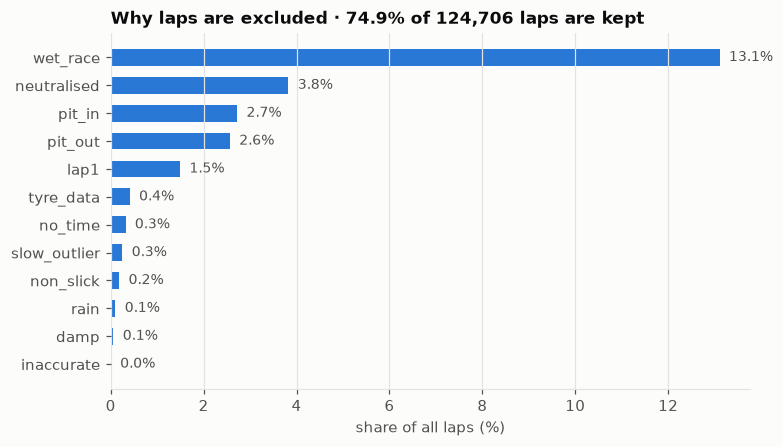

race_id,fastf1,openf1
exclude_reason,,
clean (kept),70.72,77.53
damp,0.16,0.00
inaccurate,0.01,0.00
lap1,1.48,1.50
neutralised,4.83,3.21
no_time,0.37,0.29
non_slick,0.49,0.00
pit_in,2.82,2.66
pit_out,2.45,2.64


In [4]:
reasons = laps["exclude_reason"].fillna("clean (kept)").value_counts(normalize=True) * 100
by_source = (pd.crosstab(laps["exclude_reason"].fillna("clean (kept)"),
                         laps["race_id"].map(races.set_index("race_id")["source"]),
                         normalize="columns") * 100)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
order = reasons.drop("clean (kept)").sort_values()
ax.barh(order.index, order.values, color=BLUE, height=0.6)
for y, v in enumerate(order.values):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", color=INK_2, fontsize=9)
ax.set_xlabel("share of all laps (%)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Why laps are excluded · {reasons['clean (kept)']:.1f}% of {len(laps):,} laps are kept")
save(fig, "exclusion_reasons")
plt.show()
by_source.round(2)

`wet_race` dominates: 15 races were wet enough to drop entirely. The rest are the
expected structural exclusions (pit laps, lap 1, safety cars). The two sources have similar
exclusion profiles; `tyre_data` (stint changes that don't coincide with a pit stop) is now
rare in both after anchoring OpenF1 stints on pit stops.

**Missing values among clean laps**, i.e. what the model will need to handle:

In [5]:
features = ["quali_gap_pct", "grid_position", "interval_start_s", "track_temp", "air_temp",
            "humidity", "tyre_life", "fresh_tyre", "position"]
missing = (clean[features].isna().mean() * 100).rename("missing_%").to_frame()
missing["note"] = {
    "quali_gap_pct": "no qualifying time set (crash, DNS in quali)",
    "interval_start_s": "race leader: no car ahead (free air)",
}
missing.fillna({"note": ""})

,missing_%,note
quali_gap_pct,1.159,"no qualifying time set (crash, DNS in quali)"
grid_position,0.000,
interval_start_s,5.379,race leader: no car ahead (free air)
track_temp,0.000,
air_temp,0.000,
humidity,0.000,
tyre_life,0.000,
fresh_tyre,0.000,
position,0.000,


In [6]:
split_sizes = pd.Series({k: int(clean["year"].isin(v).sum()) for k, v in SPLITS.items()},
                        name="clean laps")
bahrain_races = races[races["circuit"] == "Sakhir"].set_index("race_id")[
    ["event_name", "source", "total_laps", "n_laps", "n_clean", "clean_pct"]]
display(split_sizes.to_frame())
bahrain_races

,clean laps
train (2021–23),52113
val (2024),20558
test (2025),20719


,event_name,source,total_laps,n_laps,n_clean,clean_pct
race_id,,,,,,
2021_01,Bahrain Grand Prix,fastf1,56,1027,849,82.668
2022_01,Bahrain Grand Prix,fastf1,57,1125,893,79.378
2023_01,Bahrain Grand Prix,openf1,57,1058,915,86.484
2024_01,Bahrain Grand Prix,openf1,57,1129,1024,90.700
2025_04,Bahrain Grand Prix,openf1,57,1129,972,86.094


## 2 · Why fuel and tyre effects need pit stops to be separated

Within a stint, tyre age and lap number both rise by one per lap, so fuel burn (which makes
the car faster) and tyre wear (which makes it slower) are **perfectly collinear**. They only
come apart because a pit stop resets tyre age while the lap count keeps going. The sawtooth
below is the variation that identifies the two effects.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


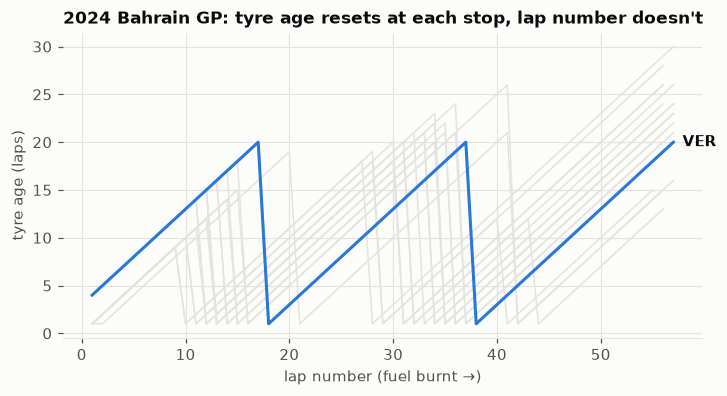

In [7]:
race = clean[clean["race_id"] == "2024_01"]
winner = race.sort_values("lap_number").groupby("driver").tail(1).sort_values("position")["driver"].iat[0]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for drv, g in laps[(laps["race_id"] == "2024_01")].groupby("driver"):
    g = g.sort_values("lap_number")
    hl = drv == winner
    ax.plot(g["lap_number"], g["tyre_life"], color=BLUE if hl else GRID,
            lw=2 if hl else 1, zorder=3 if hl else 1)
g = laps[(laps["race_id"] == "2024_01") & (laps["driver"] == winner)].sort_values("lap_number")
ax.annotate(winner, (g["lap_number"].iat[-1], g["tyre_life"].iat[-1]), xytext=(6, 0),
            textcoords="offset points", va="center", color=INK, fontweight="semibold")
ax.set_xlabel("lap number (fuel burnt →)")
ax.set_ylabel("tyre age (laps)")
ax.set_title("2024 Bahrain GP: tyre age resets at each stop, lap number doesn't")
save(fig, "tyre_age_vs_lap")
plt.show()

## 3 · A per-race decomposition model

For each Bahrain race separately (cars, tyres and track differ by year), fit by least squares:

$$\text{lap time} = \underbrace{\mu_{\text{driver, race}}}_{\text{car + driver pace}} - \beta_{\text{fuel}}\cdot\text{lap} + \alpha_c + \gamma_c\cdot\text{tyre age}$$

- $\mu$: one intercept per driver per race, absorbing car and driver pace
- $\beta_{\text{fuel}}$: time gained per lap of fuel burnt
- $\alpha_c$: fresh-tyre offset of compound $c$ (soft is the reference)
- $\gamma_c$: degradation slope of compound $c$ (s per lap of tyre age)

This is essentially baseline #2 from the design (fuel-corrected linear degradation). 95%
intervals come from a **cluster bootstrap over driver-races** (200 resamples), because laps
within a stint are strongly correlated and per-lap standard errors would be far too narrow.
Compounds with fewer than 50 clean laps in a race are flagged rather than trusted.

In [8]:
MIN_LAPS = 50


def fit_decomposition(df):
    fe = pd.get_dummies(df["driver_race"], dtype=float)
    present = [c for c in COMPOUNDS if (df["compound"] == c).any()]
    terms = {"lap_number": df["lap_number"].astype(float)}
    for c in present:
        is_c = (df["compound"] == c).astype(float)
        if c != present[0]:
            terms[f"alpha_{c}"] = is_c
        terms[f"gamma_{c}"] = is_c * df["tyre_life"]
    X = pd.concat([fe, pd.DataFrame(terms, index=df.index)], axis=1)
    beta, *_ = np.linalg.lstsq(X.to_numpy(), df["lap_time_s"].to_numpy(), rcond=None)
    coef = pd.Series(beta, index=X.columns)
    out = {"fuel": -coef["lap_number"]}
    for c in COMPOUNDS:
        out[f"deg_{c}"] = coef.get(f"gamma_{c}", np.nan)
        out[f"offset_{c}"] = coef.get(f"alpha_{c}", 0.0 if c == present[0] else np.nan)
    return out, coef, df["lap_time_s"] - X.to_numpy() @ beta


def bootstrap(df, n=200, seed=0):
    rng = np.random.default_rng(seed)
    groups = {k: g for k, g in df.groupby("driver_race")}
    units = list(groups)
    draws = []
    for _ in range(n):
        pick = rng.choice(len(units), len(units), replace=True)
        sample = pd.concat([groups[units[i]].assign(driver_race=f"{units[i]}#{j}")
                            for j, i in enumerate(pick)])
        draws.append(fit_decomposition(sample)[0])
    return pd.DataFrame(draws)


rows, fits = [], {}
for year, g in bahrain.groupby("year"):
    point, coef, resid = fit_decomposition(g)
    draws = bootstrap(g)
    fits[year] = (coef, resid)
    counts = g["compound"].value_counts()
    for name, value in point.items():
        lo, hi = draws[name].quantile([0.025, 0.975])
        compound = name.split("_")[1] if "_" in name else None
        rows.append({"year": year, "term": name, "estimate": value, "ci_low": lo, "ci_high": hi,
                     "laps": counts.get(compound, len(g)) if compound else len(g)})
est = pd.DataFrame(rows)
est["reliable"] = est["laps"] >= MIN_LAPS
est.pivot(index="year", columns="term", values="estimate")[
    ["fuel", "deg_SOFT", "deg_MEDIUM", "deg_HARD", "offset_MEDIUM", "offset_HARD"]]

term,fuel,deg_SOFT,deg_MEDIUM,deg_HARD,offset_MEDIUM,offset_HARD
year,,,,,,
2021,0.067,0.074,0.092,0.110,-0.050,-0.152
2022,0.082,0.182,0.147,0.156,0.552,0.589
2023,0.077,0.132,0.313,0.120,-0.899,0.113
2024,0.071,0.129,NaN,0.110,NaN,0.048
2025,0.062,0.121,0.102,0.114,0.257,0.250


The fresh-tyre **offsets** are the weakest part of the fit. Their intervals span a second
or more, so a single race cannot say how much faster a new soft is than a new hard:

In [9]:
offsets = est[est["term"].isin(["offset_MEDIUM", "offset_HARD"]) & est["estimate"].notna()]
offsets.assign(ci_width=offsets["ci_high"] - offsets["ci_low"])[
    ["year", "term", "estimate", "ci_low", "ci_high", "ci_width", "laps"]].round(2)

,year,term,estimate,ci_low,ci_high,ci_width,laps
4,2021,offset_MEDIUM,-0.05,-1.38,1.11,2.49,403
6,2021,offset_HARD,-0.15,-1.52,1.12,2.64,385
11,2022,offset_MEDIUM,0.55,0.16,0.92,0.76,294
13,2022,offset_HARD,0.59,0.02,1.17,1.15,91
18,2023,offset_MEDIUM,-0.90,-1.16,-0.65,0.51,8
20,2023,offset_HARD,0.11,-0.23,0.38,0.61,514
27,2024,offset_HARD,0.05,-0.34,0.35,0.69,731
32,2025,offset_MEDIUM,0.26,-0.04,0.58,0.62,455
34,2025,offset_HARD,0.25,-0.17,0.84,1.01,270


## 4 · Degradation curves by compound

Each point is the median lap time at that tyre age after removing the driver-race pace, the
fuel effect and the compound's fresh-tyre offset, so it reads as **seconds slower than a
fresh tyre of the same compound**. Lines are the fitted linear slopes $\gamma_c$; where the
points bend away from the line, degradation isn't linear.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


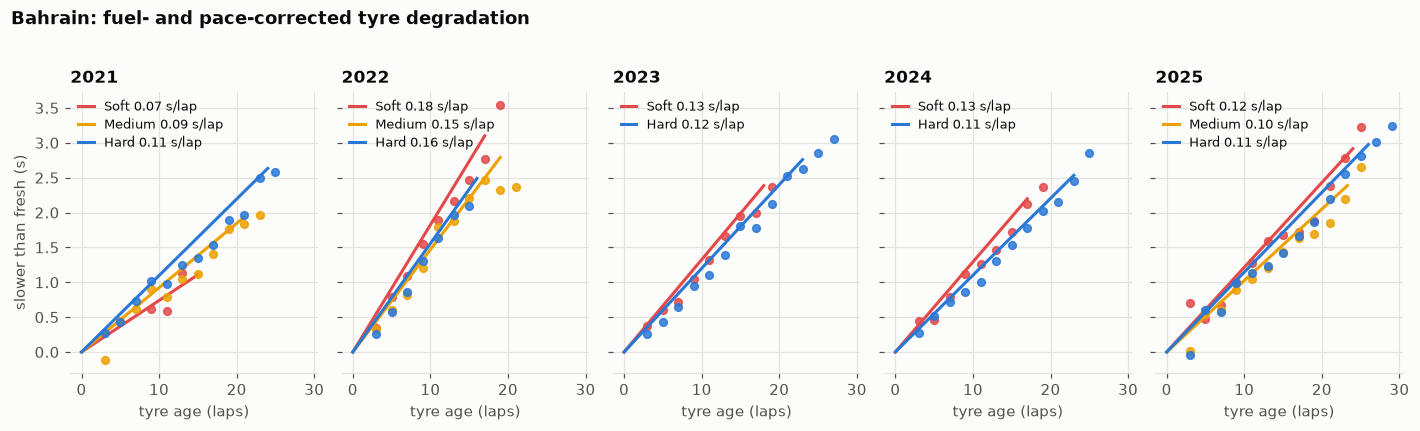

compound,SOFT,MEDIUM,HARD
year,,,
2021,0.074,0.092,0.110
2022,0.182,0.147,0.156
2023,0.132,NaN,0.120
2024,0.129,NaN,0.110
2025,0.121,0.102,0.114


In [10]:
years = sorted(bahrain["year"].unique())
fig, axes = plt.subplots(1, len(years), figsize=(13, 3.8), sharey=True, sharex=True)
curve_rows = []
for ax, year in zip(axes, years):
    coef, resid = fits[year]
    g = bahrain[bahrain["year"] == year]
    handles = []
    for c in COMPOUNDS:
        sel = g["compound"] == c
        if sel.sum() < MIN_LAPS:
            continue
        gamma = coef[f"gamma_{c}"]
        # residual + this compound's own degradation term = corrected lap-time loss vs fresh
        loss = resid[sel] + gamma * g.loc[sel, "tyre_life"]
        age_bin = (g.loc[sel, "tyre_life"] // 2) * 2 + 1
        binned = loss.groupby(age_bin).agg(["median", "size"])
        binned = binned[binned["size"] >= 8]
        ax.plot(binned.index, binned["median"], "o", color=COMPOUND_COLOR[c], ms=5, alpha=0.85)
        ages = np.array([0, g.loc[sel, "tyre_life"].quantile(0.95)])
        (line,) = ax.plot(ages, gamma * ages, color=COMPOUND_COLOR[c], lw=2,
                          label=f"{c.title()} {gamma:.2f} s/lap")
        handles.append(line)
        curve_rows.append({"year": year, "compound": c, "laps": int(sel.sum()),
                           "deg_s_per_lap": gamma, "max_age": int(g.loc[sel, "tyre_life"].max())})
    ax.legend(handles=handles, loc="upper left", fontsize=8.5, handlelength=1.2,
              borderaxespad=0.2, labelspacing=0.3)
    ax.set_title(str(year))
    ax.set_xlabel("tyre age (laps)")
axes[0].set_ylabel("slower than fresh (s)")
fig.suptitle("Bahrain: fuel- and pace-corrected tyre degradation", x=0.01, ha="left",
             fontweight="semibold", y=1.02)
fig.tight_layout()
save(fig, "bahrain_degradation")
plt.show()
pd.DataFrame(curve_rows).pivot(index="year", columns="compound", values="deg_s_per_lap")[COMPOUNDS]

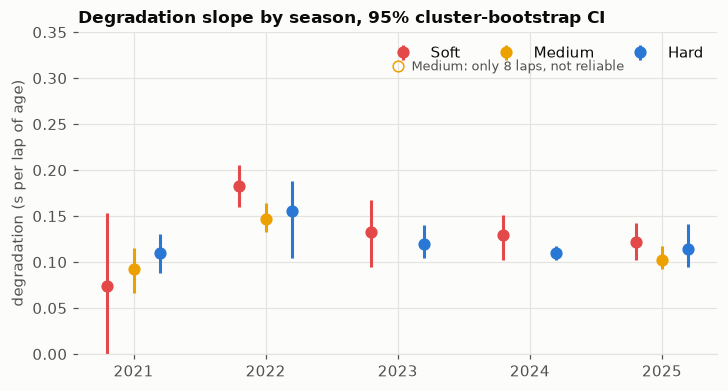

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
deg = est[est["term"].str.startswith("deg_")].copy()
deg["compound"] = deg["term"].str[4:]
for i, c in enumerate(COMPOUNDS):
    d = deg[(deg["compound"] == c) & deg["estimate"].notna()]
    x = d["year"] + (i - 1) * 0.2
    solid = d["reliable"]
    ax.errorbar(x[solid], d.loc[solid, "estimate"],
                yerr=[d.loc[solid, "estimate"] - d.loc[solid, "ci_low"],
                      d.loc[solid, "ci_high"] - d.loc[solid, "estimate"]],
                fmt="o", color=COMPOUND_COLOR[c], ms=7, capsize=0, elinewidth=2, label=c.title())
    ax.plot(x[~solid], d.loc[~solid, "estimate"], "o", mfc="none", mec=COMPOUND_COLOR[c], ms=7)
    for xi, (_, row) in zip(x[~solid], d[~solid].iterrows()):
        ax.annotate(f"{c.title()}: only {row['laps']} laps, not reliable", (xi, row["estimate"]),
                    xytext=(9, 0), textcoords="offset points", va="center", color=INK_2, fontsize=8.5)
ax.set_xticks(years)
ax.set_ylabel("degradation (s per lap of age)")
ax.set_ylim(0, 0.35)
ax.legend(ncol=3, loc="upper right")
ax.set_title("Degradation slope by season, 95% cluster-bootstrap CI")
save(fig, "bahrain_degradation_slopes")
plt.show()

## 5 · Fuel effect

The fuel coefficient is the best-identified quantity in the model. As a sanity check against
an external rule of thumb (roughly 0.03 s per kg, at very roughly 1.7–1.9 kg burnt per lap at
Bahrain, i.e. ~0.05–0.06 s/lap), the estimates should be of that order. The second panel shows
the raw evidence: lap time after removing driver pace and tyre degradation, against lap number.

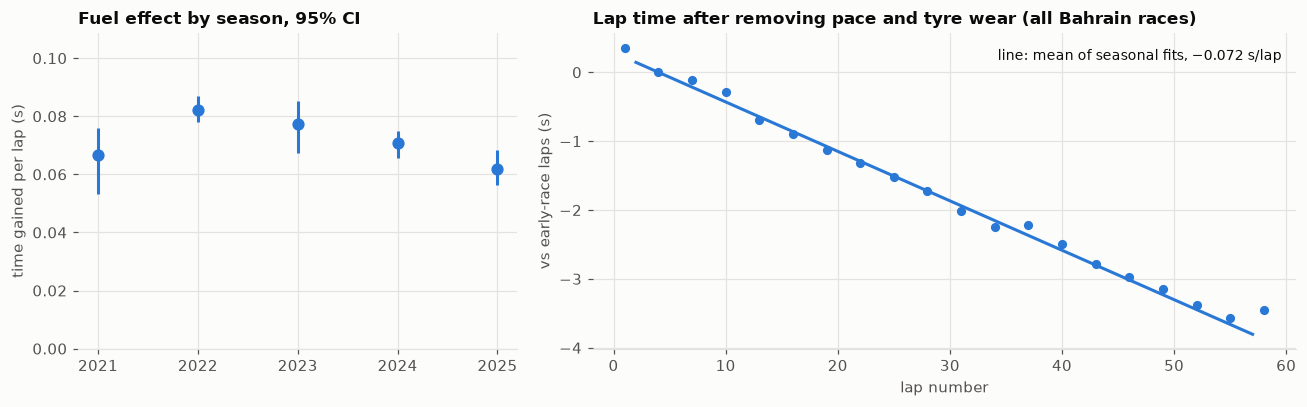

,estimate,ci_low,ci_high
year,,,
2021,0.067,0.053,0.076
2022,0.082,0.078,0.087
2023,0.077,0.067,0.085
2024,0.071,0.065,0.075
2025,0.062,0.056,0.068


In [12]:
fuel = est[est["term"] == "fuel"].set_index("year")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax1.errorbar(fuel.index, fuel["estimate"],
             yerr=[fuel["estimate"] - fuel["ci_low"], fuel["ci_high"] - fuel["estimate"]],
             fmt="o", color=BLUE, ms=7, capsize=0, elinewidth=2)
ax1.set_xticks(years)
ax1.set_ylim(0, fuel["ci_high"].max() * 1.25)
ax1.set_ylabel("time gained per lap (s)")
ax1.set_title("Fuel effect by season, 95% CI")

pooled = []
for year, (coef, resid) in fits.items():
    g = bahrain[bahrain["year"] == year]
    # residual + the fitted fuel term = lap time with only the fuel effect left in
    pooled.append(pd.DataFrame({"lap": g["lap_number"],
                                "fuel_part": resid + coef["lap_number"] * g["lap_number"]}))
pooled = pd.concat(pooled)
pooled["fuel_part"] -= pooled.loc[pooled["lap"].between(2, 6), "fuel_part"].median()
binned = pooled.groupby((pooled["lap"] // 3) * 3 + 1)["fuel_part"].median()
ax2.plot(binned.index, binned.values, "o", color=BLUE, ms=5)
slope = fuel["estimate"].mean()
xs = np.array([2, 57])
ax2.plot(xs, -slope * (xs - 4), color=BLUE, lw=2)
ax2.text(0.98, 0.95, f"line: mean of seasonal fits, −{slope:.3f} s/lap", transform=ax2.transAxes,
         ha="right", va="top", color=INK, fontsize=9)
ax2.set_xlabel("lap number")
ax2.set_ylabel("vs early-race laps (s)")
ax2.set_title("Lap time after removing pace and tyre wear (all Bahrain races)")
fig.tight_layout()
save(fig, "bahrain_fuel_effect")
plt.show()
fuel[["estimate", "ci_low", "ci_high"]]

## 6 · Traffic

`interval_start_s` is the gap to the car directly ahead when the lap starts (known before
the lap, so a model may use it). For every dry race, the decomposition model from §3 is
fitted and its residuals are grouped by that gap: a positive median means laps in that band
are slower than the driver's own race pace would predict. Bahrain is compared with all
circuits. Leaders have no car ahead.

Caveat: this is associational. A car that is close behind is often there *because* it is
faster and held up; the residual measures the time it loses relative to its own pace.

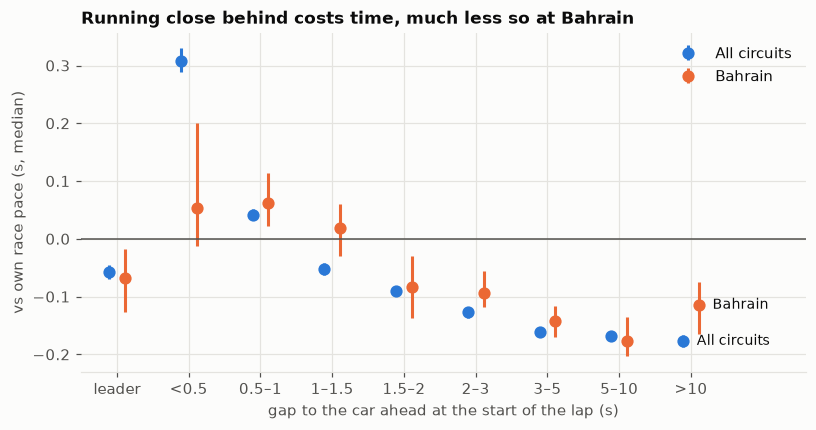

All circuits                        Bahrain                     
             median     lo     hi     laps  median     lo     hi   laps
band                                                                   
leader       -0.058 -0.069 -0.045   5023.0  -0.069 -0.126 -0.018  239.0
<0.5          0.308  0.288  0.330   6264.0   0.053 -0.012  0.201  247.0
0.5–1         0.042  0.033  0.052  15606.0   0.062  0.022  0.114  743.0
1–1.5        -0.053 -0.062 -0.042  10295.0   0.019 -0.030  0.061  488.0
1.5–2        -0.090 -0.099 -0.081   8263.0  -0.084 -0.137 -0.030  403.0
2–3          -0.127 -0.137 -0.119  11487.0  -0.095 -0.118 -0.056  567.0
3–5          -0.162 -0.169 -0.156  12855.0  -0.141 -0.170 -0.117  690.0
5–10         -0.168 -0.176 -0.161  12896.0  -0.176 -0.203 -0.134  684.0
>10          -0.177 -0.188 -0.166  10701.0  -0.114 -0.165 -0.075  592.0

In [13]:
resids = []
for race_id, g in clean.groupby("race_id"):
    if g["compound"].nunique() < 2 or len(g) < 200:
        continue
    _, _, r = fit_decomposition(g)
    resids.append(pd.DataFrame({"resid": r, "gap": g["interval_start_s"], "circuit": g["circuit"]}))
resids = pd.concat(resids)

edges = [0, 0.5, 1, 1.5, 2, 3, 5, 10, np.inf]
labels = ["<0.5", "0.5–1", "1–1.5", "1.5–2", "2–3", "3–5", "5–10", ">10"]
resids["band"] = pd.cut(resids["gap"], edges, right=False, labels=labels).astype(object)
resids.loc[resids["gap"].isna(), "band"] = "leader"
order = ["leader", *labels]


def median_ci(x, n=500, seed=0):
    rng = np.random.default_rng(seed)
    x = x.to_numpy()
    meds = np.median(rng.choice(x, (n, len(x)), replace=True), axis=1)
    return pd.Series({"median": np.median(x), "lo": np.quantile(meds, 0.025),
                      "hi": np.quantile(meds, 0.975), "laps": len(x)})


traffic = {name: d.groupby("band")["resid"].apply(median_ci).unstack().reindex(order)
           for name, d in [("All circuits", resids), ("Bahrain", resids[resids["circuit"] == "Sakhir"])]}

fig, ax = plt.subplots(figsize=(8.5, 4))
for i, (name, t) in enumerate(traffic.items()):
    x = np.arange(len(order)) + (i - 0.5) * 0.22
    color = [BLUE, ORANGE][i]
    ax.errorbar(x, t["median"], yerr=[t["median"] - t["lo"], t["hi"] - t["median"]], fmt="o",
                color=color, ms=7, capsize=0, elinewidth=2, label=name)
    ax.annotate(name, (x[-1], t["median"].iat[-1]), xytext=(9, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.axhline(0, color=INK_2, lw=1)
ax.set_xlim(-0.5, len(order) + 0.6)
ax.set_xticks(range(len(order)), order)
ax.set_xlabel("gap to the car ahead at the start of the lap (s)")
ax.set_ylabel("vs own race pace (s, median)")
ax.legend(loc="upper right")
ax.set_title("Running close behind costs time, much less so at Bahrain")
save(fig, "traffic_effect")
plt.show()
pd.concat(traffic, axis=1).round(3)

## 7 · Takeaways for modelling

| Finding | Evidence | Consequence for phase 1–2 |
|---|---|---|
| **Fuel effect is well identified and stable** | 0.062–0.082 s/lap across five seasons, tight CIs | `fuel_net` can be near-linear in laps remaining; a good term to share across circuits |
| **Degradation is roughly linear over the ages teams actually run** | 0.10–0.18 s/lap; binned medians track the lines, mild upturn only on 2022 softs | Linear-per-compound is a strong baseline. Observed ages top out ~30 laps (95th pct 15–26), so longer counterfactual stints are **extrapolation** and the UI must flag them |
| **Soft barely out-degrades hard after correction** | similar slopes most years | Strategy-driven tyre management and selection are in the data; and "SOFT" is a different Pirelli compound in different years → build the C1–C5 table before training |
| **Fresh-compound offsets are not identifiable within one race** | offset CIs ~0.6–2.6 s wide | Per-race fitting can't support strategy calls; **pooling across races** (shared model with embeddings/priors) is required. This is the core argument for the network |
| **Traffic is real and circuit-dependent** | all circuits: +0.31 s within 0.5 s of the car ahead, ~0 at 0.5–1 s (consistent with DRS), −0.16 s in clear air; Bahrain within 0.5 s: +0.05 s (CI −0.01…0.20) | `traffic_net` must take the circuit as input; gap at lap start is a legitimate feature |
| **Missing values are structural, not random** | `interval_start_s` missing = race leader; `quali_gap_pct` missing ≈1% | Encode leaders as free air (indicator + capped gap) rather than imputing; add a missing-quali indicator |
| **Order of magnitude to beat** | in-sample residual SD of this linear model at Bahrain ≈0.45–0.56 s | Phase 1 reports held-out error for this model as baseline #2 |

Caveats: all effects are associational; strategies are chosen by teams (selection),
drivers manage tyres to plan, and fuel load is a proxy. The simulator will treat these
estimates as such and label counterfactual outputs as simulated.